# PEC 2 — Técnicas de visualización aplicadas a la Fórmula 1

**Técnicas:** Heatmap · Parallel Coordinates Plot · Bump chart  
**Fuente:** [Jolpica F1 API](https://api.jolpi.ca/ergast/f1/), API abierta compatible con Ergast.

## Preguntas de análisis
1. **Heatmap:** ¿cómo se distribuyen los puntos de los pilotos carrera a carrera en 2025?
2. **Parallel Coordinates Plot:** ¿qué perfiles estadísticos distinguen a los pilotos durante 2025?
3. **Bump chart:** ¿cómo evolucionó la posición final de los pilotos entre 2021 y 2025?

El notebook descarga datos, prepara tablas reproducibles y exporta tres gráficos interactivos HTML para publicar en GitHub Pages. Requiere conexión a internet para consultar la API.

## 1. Dependencias

Instala desde una terminal con `python -m pip install -r requirements.txt`. Si falta alguna biblioteca en tu entorno, ejecuta la celda siguiente.

In [1]:
%pip install -q pandas requests plotly

Note: you may need to restart the kernel to use updated packages.


## 2. Configuración y funciones auxiliares

Jolpica recomienda enviar un `User-Agent` identificativo. Se consultan solo las temporadas necesarias y se espera brevemente entre peticiones para evitar solicitudes innecesarias.

In [4]:
from pathlib import Path
import time
import requests
import pandas as pd
import plotly.graph_objects as go

BASE_URL = "https://api.jolpi.ca/ergast/f1"
HEADERS = {"User-Agent": "PEC2Formula1Visualization/1.0 (educational project)"}
SEASONS = [2021, 2022, 2023, 2024, 2025]
HEATMAP_SEASON = 2025
OUTPUT_DIR = Path("docs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

session = requests.Session()
session.headers.update(HEADERS)


def api_get(path, params=None, retries=6):
    url = f"{BASE_URL}/{path.strip('/')}/"
    headers = {
        "User-Agent": "PEC2-Formula1-Visualization/1.0"
    }

    for attempt in range(retries):
        try:
            response = requests.get(
                url,
                params=params,
                headers=headers,
                timeout=30
            )

            if response.status_code == 429:
                retry_after = response.headers.get("Retry-After")

                try:
                    wait = float(retry_after)
                except (TypeError, ValueError):
                    wait = min(60, 5 * (2 ** attempt))

                print(
                    f"Límite de la API alcanzado. "
                    f"Esperando {wait:.0f} segundos..."
                )
                time.sleep(wait)
                continue

            response.raise_for_status()
            return response.json()

        except requests.RequestException:
            if attempt == retries - 1:
                raise

            time.sleep(min(30, 2 ** attempt))

    raise RuntimeError(
        "La API sigue limitando las peticiones. "
        "Espera un tiempo antes de volver a intentarlo."
    )

def races_from(data):
    return data.get("MRData", {}).get("RaceTable", {}).get("Races", [])

print("Fuente:", BASE_URL)

Fuente: https://api.jolpi.ca/ergast/f1


## 3. Descargar resultados de las carreras de 2025

Primero se consulta el calendario; después, los resultados de cada ronda. Así se evita depender de una única respuesta paginada que pudiera truncar resultados.

In [5]:
calendar = api_get(f"{HEATMAP_SEASON}/races", {"limit": 100})
races = races_from(calendar)
if not races:
    raise RuntimeError("La API no devolvió carreras. Comprueba la conexión o la disponibilidad del servicio.")

rows = []
for race in races:
    round_no = int(race["round"])
    result_json = api_get(f"{HEATMAP_SEASON}/{round_no}/results", {"limit": 100})
    round_races = races_from(result_json)
    if not round_races:
        continue
    for result in round_races[0].get("Results", []):
        driver = result.get("Driver", {})
        constructor = result.get("Constructor", {})
        position = result.get("position")
        grid = result.get("grid")
        rows.append({
            "season": HEATMAP_SEASON,
            "round": round_no,
            "race": race["raceName"],
            "date": race.get("date", ""),
            "driver_id": driver.get("driverId"),
            "driver": f'{driver.get("givenName", "")} {driver.get("familyName", "")}'.strip(),
            "constructor": constructor.get("name", "Unknown"),
            "points": float(result.get("points", 0) or 0),
            "position": int(position) if str(position).isdigit() else None,
            "grid": int(grid) if str(grid).isdigit() else None,
            "status": result.get("status", ""),
        })
    time.sleep(0.15)

results_2025 = pd.DataFrame(rows)
if results_2025.empty:
    raise RuntimeError("No se pudieron obtener resultados de 2025.")
race_order = (results_2025[["round", "race"]].drop_duplicates()
              .sort_values("round")["race"].tolist())
print("Carreras:", results_2025["round"].nunique(), "| Registros:", len(results_2025))
display(results_2025.head())

Límite de la API alcanzado. Esperando 10 segundos...
Carreras: 24 | Registros: 479


,season,round,race,date,driver_id,driver,constructor,points,position,grid,status
0,2025,1,Australian Grand Prix,2025-03-16,norris,Lando Norris,McLaren,25.0,1,1,Finished
1,2025,1,Australian Grand Prix,2025-03-16,max_verstappen,Max Verstappen,Red Bull,18.0,2,3,Finished
2,2025,1,Australian Grand Prix,2025-03-16,russell,George Russell,Mercedes,15.0,3,4,Finished
3,2025,1,Australian Grand Prix,2025-03-16,antonelli,Andrea Kimi Antonelli,Mercedes,12.0,4,16,Finished
4,2025,1,Australian Grand Prix,2025-03-16,albon,Alexander Albon,Williams,10.0,5,6,Finished


## 4. Visualización 1 — Heatmap de puntos por carrera

**Pregunta:** ¿en qué Grandes Premios obtuvo cada piloto más puntos?

- Filas: pilotos.
- Columnas: carreras en orden cronológico.
- Color y valor: puntos obtenidos.
- Los pilotos se ordenan por puntos totales de la temporada.

Los valores ausentes se dejan como celdas vacías, en lugar de asumir automáticamente que son cero.

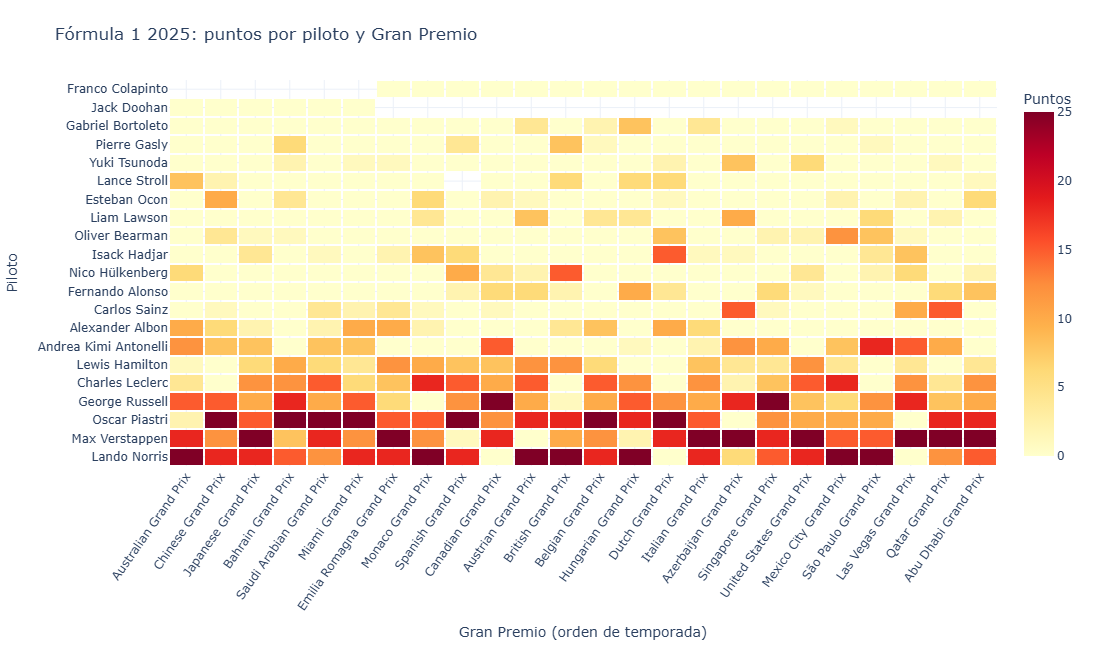

Exportado: docs\heatmap.html


In [6]:
matrix = results_2025.pivot_table(
    index="driver", columns="race", values="points", aggfunc="sum"
).reindex(columns=race_order)
driver_order = results_2025.groupby("driver")["points"].sum().sort_values(ascending=False).index
matrix = matrix.reindex(driver_order)

heatmap = go.Figure(go.Heatmap(
    z=matrix.values, x=matrix.columns, y=matrix.index,
    colorscale="YlOrRd", colorbar={"title": "Puntos"},
    xgap=2, ygap=2,
    hovertemplate="Piloto: %{y}<br>Gran Premio: %{x}<br>Puntos: %{z}<extra></extra>"
))
heatmap.update_layout(
    title="Fórmula 1 2025: puntos por piloto y Gran Premio",
    xaxis_title="Gran Premio (orden de temporada)", yaxis_title="Piloto",
    template="plotly_white", height=max(650, 28 * len(matrix)),
    margin=dict(l=150, r=30, t=80, b=160)
)
heatmap.update_xaxes(tickangle=-55)
heatmap.show()
heatmap.write_html(OUTPUT_DIR / "heatmap.html", include_plotlyjs=True, full_html=True)
print("Exportado:", OUTPUT_DIR / "heatmap.html")

### Cómo interpretar el heatmap
Las filas con colores intensos de forma recurrente indican regularidad; las celdas aisladas con puntuaciones altas señalan resultados destacados. Se representan puntos, no posiciones. El gráfico no incluye las carreras sprint como una sesión independiente: representa los resultados de los Grandes Premios.

## 5. Estadísticas de pilotos para 2025

Calculamos puntos, victorias, podios, posición media de llegada entre resultados clasificados, salidas desde la primera posición de parrilla y resultados sin posición numérica. Esta última métrica es una aproximación operativa, no una clasificación exhaustiva de todos los tipos de abandono.

In [7]:
def summarize_driver(group):
    classified = group[group["position"].notna()]
    return pd.Series({
        "points": group["points"].sum(),
        "wins": int((group["position"] == 1).sum()),
        "podiums": int(group["position"].isin([1, 2, 3]).sum()),
        "mean_finish": classified["position"].mean() if not classified.empty else None,
        "pole_starts": int((group["grid"] == 1).sum()),
        "non_classified": int(group["position"].isna().sum()),
        "races_recorded": int(group["round"].nunique()),
        "constructor": group["constructor"].mode().iloc[0] if not group["constructor"].mode().empty else "Unknown",
    })

driver_stats = (results_2025.groupby(["driver_id", "driver"], dropna=False)
                .apply(summarize_driver, include_groups=False).reset_index()
                .sort_values("points", ascending=False).reset_index(drop=True))
display(driver_stats.head(10))

,driver_id,driver,points,wins,podiums,mean_finish,pole_starts,non_classified,races_recorded,constructor
0,norris,Lando Norris,394.0,7,18,4.250000,7,0,24,McLaren
1,max_verstappen,Max Verstappen,389.0,8,15,3.666667,8,0,24,Red Bull
2,piastri,Oscar Piastri,381.0,7,16,4.208333,6,0,24,McLaren
3,russell,George Russell,289.0,2,9,4.541667,2,0,24,Mercedes
4,leclerc,Charles Leclerc,225.0,0,7,6.750000,1,0,24,Ferrari
5,antonelli,Andrea Kimi Antonelli,135.0,0,3,9.833333,0,0,24,Mercedes
6,hamilton,Lewis Hamilton,135.0,0,0,8.500000,0,0,24,Ferrari
7,albon,Alexander Albon,70.0,0,0,11.041667,0,0,24,Williams
8,sainz,Carlos Sainz,54.0,0,2,12.166667,0,0,24,Williams
9,alonso,Fernando Alonso,51.0,0,0,11.875000,0,0,24,Aston Martin


## 6. Visualización 2 — Parallel Coordinates Plot

**Pregunta:** ¿qué perfiles estadísticos distinguen a los pilotos de 2025?

Cada línea representa un piloto y cada eje una métrica. Para poder comparar variables con unidades diferentes, se normalizan entre 0 y 1. La posición media se invierte para que un valor más alto represente una mejor posición media. La escala normalizada es relativa a los valores observados; no representa unidades originales.

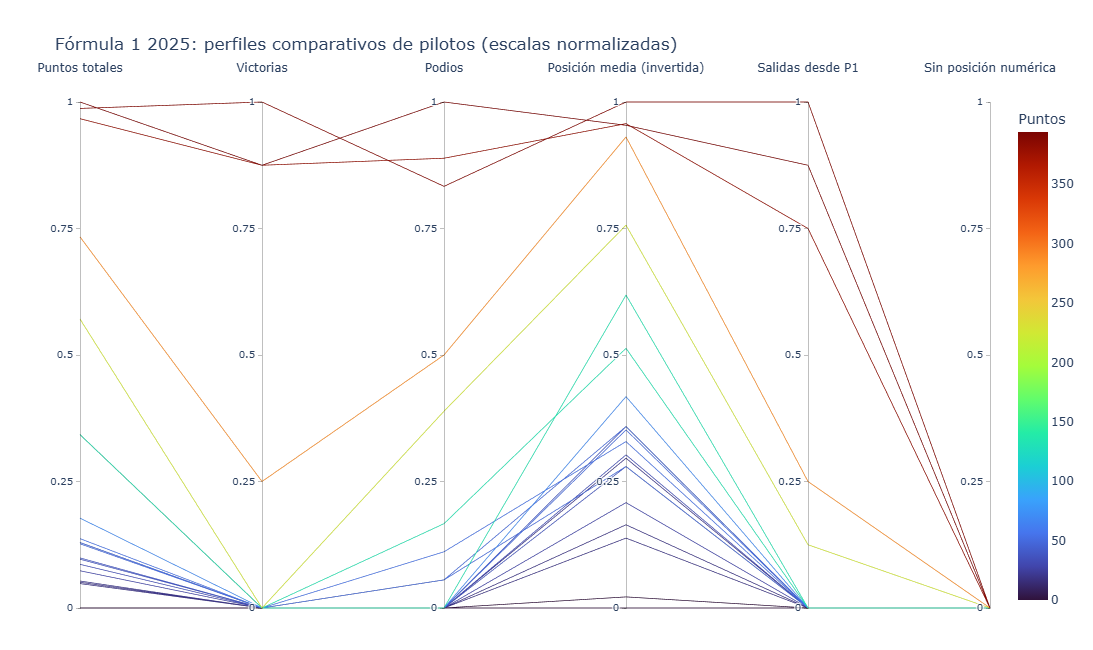

Exportado: docs\parallel-coordinates.html


In [8]:
metrics = ["points", "wins", "podiums", "mean_finish", "pole_starts", "non_classified"]
parallel_data = driver_stats[["driver", "constructor"] + metrics].copy()
parallel_data["mean_finish_quality"] = (
    parallel_data["mean_finish"].max() - parallel_data["mean_finish"] + parallel_data["mean_finish"].min()
)
plot_metrics = ["points", "wins", "podiums", "mean_finish_quality", "pole_starts", "non_classified"]
labels = {
    "points": "Puntos totales", "wins": "Victorias", "podiums": "Podios",
    "mean_finish_quality": "Posición media (invertida)",
    "pole_starts": "Salidas desde P1", "non_classified": "Sin posición numérica"
}
scaled = parallel_data[plot_metrics].astype(float).copy()
for col in scaled.columns:
    low, high = scaled[col].min(), scaled[col].max()
    scaled[col] = 0.0 if high == low else (scaled[col] - low) / (high - low)

dimensions = [
    {"label": labels[col], "values": scaled[col], "range": [0, 1],
     "tickvals": [0, .25, .5, .75, 1],
     "ticktext": ["0", "0.25", "0.5", "0.75", "1"]}
    for col in plot_metrics
]
parallel = go.Figure(go.Parcoords(
    line=dict(color=driver_stats["points"], colorscale="Turbo", showscale=True,
              colorbar=dict(title="Puntos")),
    dimensions=dimensions, labelfont=dict(size=12), tickfont=dict(size=10)
))
parallel.update_layout(
    title="Fórmula 1 2025: perfiles comparativos de pilotos (escalas normalizadas)",
    template="plotly_white", height=650, margin=dict(l=80, r=80, t=100, b=40)
)
parallel.show()
parallel.write_html(OUTPUT_DIR / "parallel-coordinates.html", include_plotlyjs=True, full_html=True)
print("Exportado:", OUTPUT_DIR / "parallel-coordinates.html")

### Cómo interpretar el Parallel Coordinates Plot
Busca líneas con valores relativamente altos en puntos, victorias y podios, y observa si coinciden con mejores posiciones medias. Los abandonos ayudan a explorar fiabilidad. Como los ejes están normalizados, usa la tabla de estadísticas para consultar valores reales. El gráfico permite explorar patrones, pero no demuestra causalidad.

## 7. Descargar las clasificaciones finales de 2021–2025

Para el bump chart se consultan las posiciones finales oficiales de cada temporada, no una clasificación parcial de una carrera concreta.

In [9]:
standings_rows = []
for season in SEASONS:
    data = api_get(f"{season}/driverstandings", {"limit": 100})
    lists = data.get("MRData", {}).get("StandingsTable", {}).get("StandingsLists", [])
    if not lists:
        print("Aviso: no hay clasificación para", season)
        continue
    for item in lists[0].get("DriverStandings", []):
        driver = item.get("Driver", {})
        constructors = item.get("Constructors", [])
        pos = item.get("position")
        standings_rows.append({
            "season": int(season),
            "driver_id": driver.get("driverId"),
            "driver": f'{driver.get("givenName", "")} {driver.get("familyName", "")}'.strip(),
            "position": int(pos) if str(pos).isdigit() else None,
            "points": float(item.get("points", 0) or 0),
            "wins": int(item.get("wins", 0) or 0),
            "constructor": constructors[-1].get("name", "Unknown") if constructors else "Unknown",
        })
    time.sleep(0.15)

standings = pd.DataFrame(standings_rows).dropna(subset=["position"])
if standings.empty:
    raise RuntimeError("No se pudieron recuperar las clasificaciones históricas.")
display(standings.sort_values(["season", "position"]).groupby("season").head(5))

,season,driver_id,driver,position,points,wins,constructor
0,2021,max_verstappen,Max Verstappen,1,395.5,10,Red Bull
1,2021,hamilton,Lewis Hamilton,2,387.5,8,Mercedes
2,2021,bottas,Valtteri Bottas,3,226.0,1,Mercedes
3,2021,perez,Sergio Pérez,4,190.0,1,Red Bull
4,2021,sainz,Carlos Sainz,5,164.5,0,Ferrari
21,2022,max_verstappen,Max Verstappen,1,454.0,15,Red Bull
22,2022,leclerc,Charles Leclerc,2,308.0,3,Ferrari
23,2022,perez,Sergio Pérez,3,305.0,2,Red Bull
24,2022,russell,George Russell,4,275.0,1,Mercedes
25,2022,sainz,Carlos Sainz,5,246.0,1,Ferrari


## 8. Visualización 3 — Bump chart de posiciones finales

**Pregunta:** ¿cómo cambió la posición final de los pilotos entre 2021 y 2025?

Para evitar saturación se seleccionan hasta diez pilotos con más temporadas presentes en las clasificaciones; los empates se resuelven por su mejor puesto histórico. El puesto mostrado sigue siendo el oficial entre todos los pilotos clasificados, no un ranking recalculado entre los seleccionados.

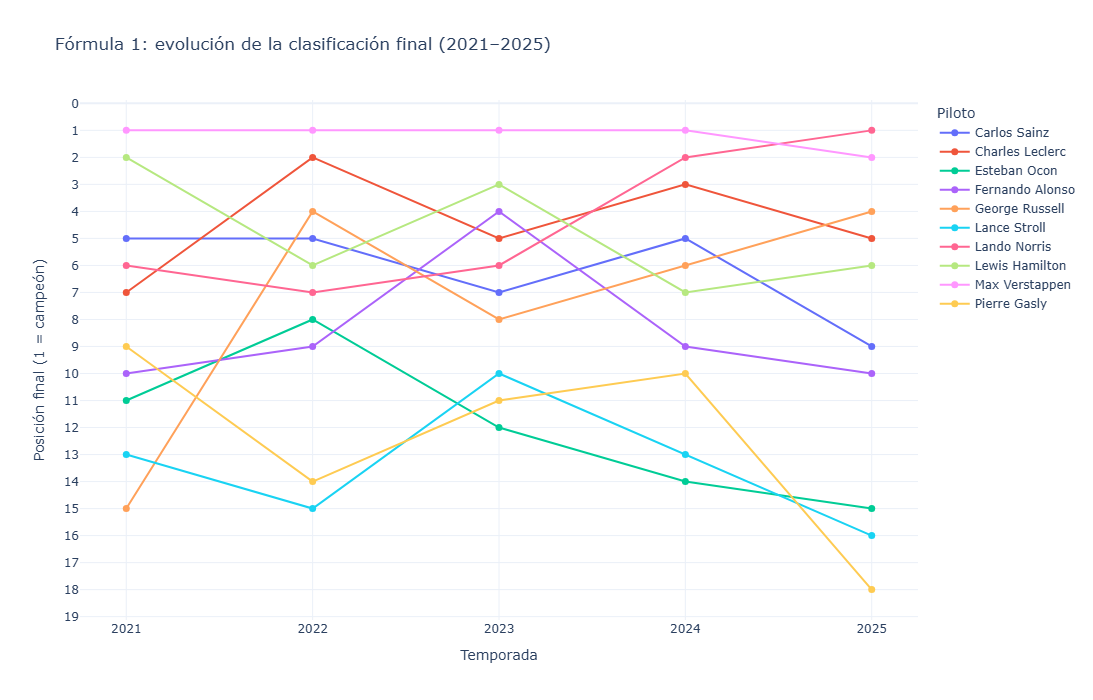

Exportado: docs\bump-chart.html


In [10]:
presence = standings.groupby("driver_id")["season"].nunique()
best = standings.groupby("driver_id")["position"].min()
selected_ids = (pd.DataFrame({"seasons": presence, "best": best})
                .sort_values(["seasons", "best"], ascending=[False, True])
                .head(10).index.tolist())
bump_data = standings[standings["driver_id"].isin(selected_ids)].copy()

bump = go.Figure()
for driver, group in bump_data.groupby("driver"):
    group = group.sort_values("season")
    bump.add_trace(go.Scatter(
        x=group["season"], y=group["position"], mode="lines+markers", name=driver,
        line=dict(width=2), marker=dict(size=7),
        customdata=group[["points", "wins", "constructor"]].to_numpy(),
        hovertemplate=(
            "Piloto: " + driver + "<br>Temporada: %{x}<br>Posición final: %{y}"
            "<br>Puntos: %{customdata[0]}<br>Victorias: %{customdata[1]}"
            "<br>Equipo: %{customdata[2]}<extra></extra>"
        )
    ))

max_pos = int(standings["position"].max())
bump.update_layout(
    title="Fórmula 1: evolución de la clasificación final (2021–2025)",
    xaxis_title="Temporada", yaxis_title="Posición final (1 = campeón)",
    xaxis=dict(tickmode="linear", dtick=1),
    yaxis=dict(autorange="reversed", dtick=1, range=[max_pos + .5, .5]),
    template="plotly_white", hovermode="closest", height=700, legend_title="Piloto"
)
bump.show()
bump.write_html(OUTPUT_DIR / "bump-chart.html", include_plotlyjs=True, full_html=True)
print("Exportado:", OUTPUT_DIR / "bump-chart.html")

### Cómo interpretar el bump chart
Una línea que sube en la pantalla indica mejora de posición, porque el eje está invertido y el primer puesto aparece arriba. Los cruces reflejan cambios relativos en la clasificación; la distancia vertical representa puestos, no puntos. Si un piloto no aparece en una temporada, no debe interpretarse automáticamente como descenso.

## 9. Página de inicio para GitHub Pages

La siguiente celda crea una página con enlaces relativos a los tres gráficos. Al ejecutar todo el notebook, la carpeta `docs/` quedará preparada para publicar.

In [11]:
index_html = (
'<!doctype html>\\n'
'<html lang="es"><head><meta charset="utf-8">\\n'
'<meta name="viewport" content="width=device-width, initial-scale=1">\\n'
'<title>PEC 2 · Visualización de Fórmula 1</title>\\n'
'<style>body{font-family:system-ui,sans-serif;max-width:880px;margin:48px auto;padding:0 20px;line-height:1.6;color:#17202a}'
'.cards{display:grid;grid-template-columns:repeat(auto-fit,minmax(220px,1fr));gap:16px;margin-top:24px}'
'article{border:1px solid #d9dee5;border-radius:14px;padding:18px}a{color:#0759a5;font-weight:650}small{color:#586575}</style></head><body>\\n'
'<h1>Visualización de datos de Fórmula 1</h1>\\n'
'<p>PEC 2 · Tres técnicas aplicadas a resultados históricos.</p>\\n'
'<div class="cards">\\n'
'<article><h2>Heatmap</h2><p>Puntos por piloto y Gran Premio en 2025.</p><a href="heatmap.html">Abrir visualización →</a></article>\\n'
'<article><h2>Parallel Coordinates Plot</h2><p>Perfiles estadísticos de pilotos en 2025.</p><a href="parallel-coordinates.html">Abrir visualización →</a></article>\\n'
'<article><h2>Bump chart</h2><p>Posiciones finales entre 2021 y 2025.</p><a href="bump-chart.html">Abrir visualización →</a></article>\\n'
'</div><p><small>Fuente: Jolpica F1 API, compatible con Ergast. Verifica las condiciones de uso y cita la fuente en la entrega.</small></p></body></html>'
)
(OUTPUT_DIR / "index.html").write_text(index_html, encoding="utf-8")
print("Página de inicio:", OUTPUT_DIR / "index.html")
print("HTML exportados:")
for path in sorted(OUTPUT_DIR.glob("*.html")):
    print(" -", path)

Página de inicio: docs\index.html
HTML exportados:
 - docs\bump-chart.html
 - docs\heatmap.html
 - docs\index.html
 - docs\parallel-coordinates.html


## 10. Checklist antes de entregar

- [ ] Ejecutar todas las celdas de arriba abajo.
- [ ] Comprobar que la API devolvió carreras y clasificaciones de todas las temporadas.
- [ ] Revisar etiquetas, escalas y tooltips.
- [ ] Confirmar que `docs/` contiene `index.html` y los tres gráficos.
- [ ] Publicar la carpeta `docs/` con GitHub Pages y probar las URL sin iniciar sesión.
- [ ] Explicar en el vídeo la normalización de las coordenadas paralelas y las limitaciones de cada técnica.

### Fuente y atribución
Jolpica F1 es una API comunitaria de código abierto y sucesora compatible de Ergast. Consulta la [documentación oficial](https://github.com/jolpica/jolpica-f1), los [resultados](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/results.md) y la [clasificación de pilotos](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/driverStandings.md). La estructura del servicio puede cambiar; si falla la descarga, revisa la documentación y los límites de uso.